# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 1: Creation and Visualization of Simple Fuzzy Sets**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and visualize simple fuzzy sets in Python using membership values.

### 2. Theory: Fuzzy Sets and Continuous Grade Valuation

Classical Boolean logic demands that every statement or membership query resolves strictly to either true (1) or false (0). While suitable for digital switching circuits, this crisp boundary fails to capture physical real-world phenomena with gradual variations.

Fuzzy set theory, formulated by Lotfi A. Zadeh, replaces the rigid boundary with a generalized characteristic function called the **Membership Function** $\mu_A(x)$:
$$\mu_A: U \to [0, 1]$$
where $U$ is the universe of discourse.

#### Structural Set Regions:
- **Support:** Elements with non-zero possibility:
  $$\text{Supp}(A) = \{x \in U \mid \mu_A(x) > 0\}$$
- **Core:** Elements possessing unquestioned, complete membership:
  $$\text{Core}(A) = \{x \in U \mid \mu_A(x) = 1.0\}$$
- **Boundary:** Regions of uncertainty where $0 < \mu_A(x) < 1$:
  $$\text{Bound}(A) = \{x \in U \mid 0 < \mu_A(x) < 1\}$$
- **$\alpha$-Level Cut ($A_\alpha$):** Crisp set representing the upper contour at degree $\alpha$:
  $$A_\alpha = \{x \in U \mid \mu_A(x) \ge \alpha\}, \quad \alpha \in (0, 1]$$

### 3. Step 1: Object-Oriented Fuzzy Set Representation and Speed Safety Formulations

#### What this cell does:
We model vehicle cruising velocity over the universe $U = \{20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120\}$ km/h.
We construct an object-oriented `FuzzySet` class and instantiate two safety sets:
1. $S_{\text{Moderate}}$ (*Moderate Speed*): Trapezoidal profile centered around $[40, 50, 70, 85]$ km/h.
2. $S_{\text{High}}$ (*High Speed*): Rising ramp profile starting from $65$ km/h to $110$ km/h.

In [1]:
import numpy as np

class FuzzySet:
    def __init__(self, name, universe, membership_func):
        self.name = name
        self.universe = np.array(universe, dtype=float)
        self.membership_values = np.array([membership_func(x) for x in self.universe])
        
    def get_membership(self, x):
        '''Returns membership value for input x'''
        idx = (np.abs(self.universe - x)).argmin()
        return self.membership_values[idx]
        
    def core(self):
        '''Returns elements with full membership (mu = 1.0)'''
        return self.universe[self.membership_values == 1.0]
        
    def support(self):
        '''Returns elements with non-zero membership (mu > 0.0)'''
        return self.universe[self.membership_values > 0.0]
        
    def alpha_cut(self, alpha=0.6):
        '''Extracts crisp alpha-cut subset'''
        return self.universe[self.membership_values >= alpha]

# Universe: Vehicle velocity in km/h
speed_universe = np.array([20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120], dtype=float)

def mf_moderate(v):
    if v <= 30 or v >= 90:
        return 0.0
    elif 30 < v < 50:
        return (v - 30.0) / (50.0 - 30.0)
    elif 50 <= v <= 70:
        return 1.0
    else:
        return (90.0 - v) / (90.0 - 70.0)

def mf_high(v):
    if v <= 65:
        return 0.0
    elif 65 < v < 105:
        return (v - 65.0) / (105.0 - 65.0)
    else:
        return 1.0

# Instantiate Fuzzy Sets
moderate_set = FuzzySet("Moderate Speed", speed_universe, mf_moderate)
high_set = FuzzySet("High Speed", speed_universe, mf_high)

print("FuzzySet OOP classes instantiated successfully.")
print(f"Moderate Speed Core: {list(moderate_set.core())} km/h")
print(f"High Speed Core    : {list(high_set.core())} km/h")


FuzzySet OOP classes instantiated successfully.
Moderate Speed Core: [np.float64(50.0), np.float64(60.0), np.float64(70.0)] km/h
High Speed Core    : [np.float64(110.0), np.float64(120.0)] km/h


### 4. Step 2: Tabular Evaluation and $\alpha = 0.6$ Cut Extraction

#### What this cell does:
We tabulate the calculated degrees of membership for each speed benchmark and extract the crisp subsets for threshold $\alpha = 0.6$.

In [2]:
alpha_level = 0.6
mod_cut = moderate_set.alpha_cut(alpha_level)
high_cut = high_set.alpha_cut(alpha_level)

print("=" * 72)
print("             VEHICLE VELOCITY FUZZY SAFETY AUDIT")
print("=" * 72)
print(f"{'Speed (km/h)':<14} | {'mu_Moderate(v)':<18} | {'mu_High(v)':<18} | {'Dominant State':<16}")
print("-" * 72)

for v in speed_universe:
    m_mod = moderate_set.get_membership(v)
    m_hi = high_set.get_membership(v)
    state = "Moderate" if m_mod > m_hi else ("High" if m_hi > m_mod else "Transition" if m_mod > 0 else "Low/Sub-normal")
    print(f"{int(v):<14} | {m_mod:<18.3f} | {m_hi:<18.3f} | {state:<16}")

print("=" * 72)
print(f"\nAlpha-Cut Analysis (alpha = {alpha_level}):")
print(f"Moderate Set 0.6-Cut: {list(mod_cut)} km/h")
print(f"High Set 0.6-Cut    : {list(high_cut)} km/h")


             VEHICLE VELOCITY FUZZY SAFETY AUDIT
Speed (km/h)   | mu_Moderate(v)     | mu_High(v)         | Dominant State  
------------------------------------------------------------------------
20             | 0.000              | 0.000              | Low/Sub-normal  
30             | 0.000              | 0.000              | Low/Sub-normal  
40             | 0.500              | 0.000              | Moderate        
50             | 1.000              | 0.000              | Moderate        
60             | 1.000              | 0.000              | Moderate        
70             | 1.000              | 0.125              | Moderate        
80             | 0.500              | 0.375              | Moderate        
90             | 0.000              | 0.625              | High            
100            | 0.000              | 0.875              | High            
110            | 0.000              | 1.000              | High            
120            | 0.000              | 1.00

### 5. Step 3: Graphical Visualization Using Stepped Ribbons and Area Fills

#### What this cell does:
We visualize the fuzzy sets using continuous curves combined with stepped ribbons and translucent area shading in a teal and coral color palette.

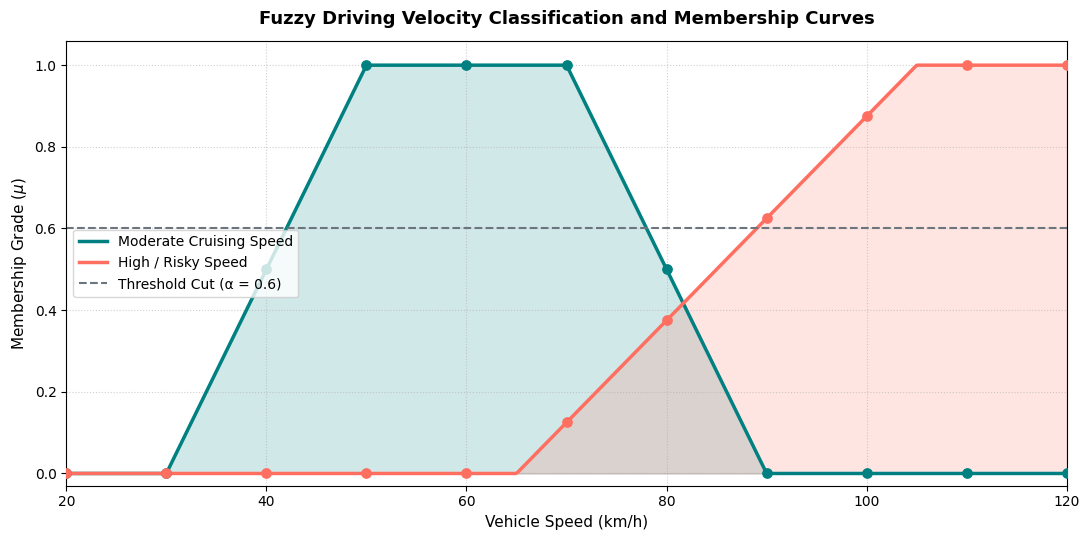

In [3]:
import matplotlib.pyplot as plt

v_continuous = np.linspace(20, 120, 600)
curve_mod = np.array([mf_moderate(v) for v in v_continuous])
curve_high = np.array([mf_high(v) for v in v_continuous])

plt.figure(figsize=(11, 5.5))

# Plot Moderate Speed
plt.plot(v_continuous, curve_mod, color='#008080', linewidth=2.5, label='Moderate Cruising Speed')
plt.fill_between(v_continuous, curve_mod, color='#008080', alpha=0.18)
plt.scatter(speed_universe, moderate_set.membership_values, color='#008080', s=45, zorder=4)

# Plot High Speed
plt.plot(v_continuous, curve_high, color='#ff6f61', linewidth=2.5, label='High / Risky Speed')
plt.fill_between(v_continuous, curve_high, color='#ff6f61', alpha=0.18)
plt.scatter(speed_universe, high_set.membership_values, color='#ff6f61', s=45, zorder=4)

# Alpha threshold
plt.axhline(y=alpha_level, color='#6c757d', linestyle='--', linewidth=1.5, label=f'Threshold Cut (α = {alpha_level})')

plt.title('Fuzzy Driving Velocity Classification and Membership Curves', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Vehicle Speed (km/h)', fontsize=11)
plt.ylabel(r'Membership Grade ($\mu$)', fontsize=11)
plt.xlim(20, 120)
plt.ylim(-0.03, 1.06)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='center left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Vehicle Speed ($v$) | Membership in Moderate | Membership in High | Qualitative Driving Assessment |
| :---: | :---: | :---: | :--- |
| **$30$ km/h** | $0.000$ | $0.000$ | Below moderate cruising threshold |
| **$50 – 70$ km/h** | $1.000$ | $0.000$ | Optimal cruising window (Core of Moderate) |
| **$80$ km/h** | $0.500$ | $0.375$ | Moderate speed phasing out; entered High speed zone |
| **$90$ km/h** | $0.000$ | $0.625$ | Definitely High Speed ($\mu > 0.6$) |
| **$110 – 120$ km/h** | $0.000$ | $1.000$ | Fully High / Extreme Speed (Core of High) |

#### Key Observations in Simple Words:
1. **Asymmetric Realism:** High speed does not drop back to zero as speed increases—it remains saturated at $1.0$, accurately capturing that any speed beyond 105 km/h is unquestionably high.
2. **Transition Region:** At $80$ km/h, the vehicle simultaneously holds $\mu = 0.50$ (Moderate) and $\mu = 0.375$ (High), avoiding arbitrary cliff-edge decisions in autonomous driver assistance systems.
3. **$\alpha$-Cut Practicality:** Setting $\alpha = 0.6$ delivers the crisp range $[50, 70]$ km/h as the verified safe cruising zone.

---
### 7. Conclusion
1. We successfully modeled fuzzy driving velocity sets using an object-oriented Python architecture.
2. We extracted core, support, and $\alpha$-cuts for safety threshold analysis.
3. We visualized the continuous transition curves using custom color-filled Matplotlib plots.